# 01 · Quickstart

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/james-kidd/pbn-notebooks/blob/main/notebooks/01_quickstart.ipynb)

A sixty-second tour: take an image, cut it into regions, and check the
result is structurally sound.

Everything downstream — paint-by-number templates, land-use costing,
infrastructure siting — is built on the two steps in this notebook.

**Running this:** in Colab, press the badge and run all. Locally,
`jupyter lab` from the repo root. Either way the first cell sorts out
dependencies and the toolkit checkout.

In [1]:
# Bootstrap: clones what it needs in Colab, finds what exists locally.
import pathlib, subprocess, sys

def _repo_root():
    for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (base / "nbtools" / "bootstrap.py").exists():
            return base
    dest = (pathlib.Path("/content/pbn-notebooks") if pathlib.Path("/content").is_dir()
            else pathlib.Path.cwd() / "pbn-notebooks")
    if not (dest / "nbtools").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--quiet",
                        "https://github.com/james-kidd/pbn-notebooks.git", str(dest)],
                       check=True)
    return dest

sys.path.insert(0, str(_repo_root()))
from nbtools.bootstrap import setup

tk = setup()                           # installs anything missing, first
from nbtools import scenes, display    # these need cv2/matplotlib, so: after

toolkit   /home/user/pbn-gradio  (found locally)
modules   geo, land_use, optimize, pipeline, segmenters, siting, topology
installed scipy, scikit-image, scikit-learn, opencv-python-headless
gradio    stubbed (UI layer not needed for these demos)


## A scene to work on

Synthetic, because the ground truth is then known by construction — when
the labeller later claims it found a pond, you can check that against the
code that drew the pond.

`scenes.swap_in_real_imagery("photo.jpg")` substitutes a photograph.

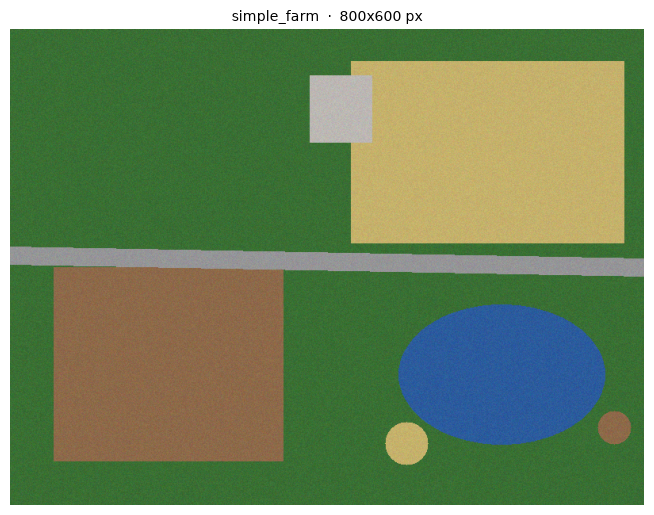

In [2]:
image = scenes.simple_farm()
display.show(image, f"simple_farm  ·  {image.shape[1]}x{image.shape[0]} px")

## Two steps to regions

Segmentation happens in the perceptually-uniform CIELAB space rather than
RGB, so "similar colour" means similar *to a viewer*. Then one call cuts
the image into regions.

The stages after the backend — merge, drop, fill — are each optional and
each independent of which backend ran. `describe()` reports what actually
happened, which is worth reading rather than assuming.

In [3]:
working = tk.pipeline.load_and_resize(image, 800)
lab = tk.pipeline.preprocess_rgb(working)

result = tk.segmenters.segment(
    lab, backend="felzenszwalb",
    merge_threshold=8.0,   # collapse adjacent regions closer than this in LAB
    min_area=480,          # drop specks
    fill=True,             # absorb the dropped specks into their neighbours
    n_segments=900,
    sigma=2.0,             # see notebook 06 on why this matters
)
print(result.describe())

felzenszwalb → merge<8 → drop<480px → fill-gaps (9 regions)


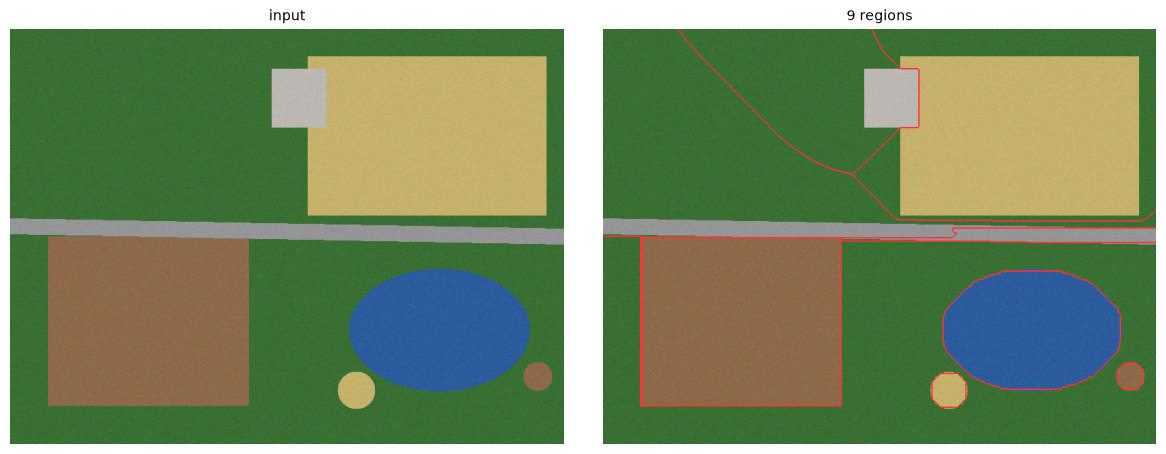

In [4]:
overlay = tk.pipeline.render_segmentation_overlay(working, result.labels)
display.grid([working, overlay], ["input", f"{result.n_regions} regions"], columns=2)

## Is the result sound?

A segmentation into connected regions is a *planar subdivision*, so its
adjacency graph must be planar. That gives hard invariants — `E ≤ 3V − 6`,
mean degree below 6, every label a single connected blob — which hold for
any correct segmentation and fail for a broken one.

Checking them is not ceremony. A label covering two disconnected blobs
silently invalidates every adjacency-derived feature computed later, and
this catches it immediately. Notebook 05 feeds the checks deliberately
broken input to prove they can fail.

In [5]:
graph = tk.topology.build_region_graph(result.labels)
checks = tk.topology.check_planarity(graph, result.labels)

display.table(
    [
        ["Vertices (regions)", checks["V"], ""],
        ["Edges (shared borders)", checks["E"], f"bound 3V-6 = {checks['edge_bound']}"],
        ["Faces (Euler V-E+F=2)", checks["faces"], ""],
        ["Mean degree", f"{checks['mean_degree']:.2f}", "must be < 6"],
        ["Disconnected regions", len(checks["disconnected_regions"]), "must be 0"],
        ["**Well formed**", "**yes**" if checks["well_formed"] else "**NO**", ""],
    ],
    ["Property", "Value", "Constraint"],
)

| Property | Value | Constraint |
|---|---|---|
| Vertices (regions) | 9 |  |
| Edges (shared borders) | 12 | bound 3V-6 = 21 |
| Faces (Euler V-E+F=2) | 5 |  |
| Mean degree | 2.67 | must be < 6 |
| Disconnected regions | 0 | must be 0 |
| **Well formed** | **yes** |  |

## Where next

| Notebook | What it covers |
|---|---|
| `02_segmentation_backends` | SLIC vs Felzenszwalb vs watershed, and why RAG merging is not one of them |
| `03_paint_by_number` | The original application, end to end |
| `04_land_use_and_features` | Labelling regions, costing them, exporting features for a model |
| `05_topology_invariants` | The planar-graph checks, tested against deliberately broken input |
| `06_siting_and_lp` | Least-cost corridor routing and linear-programming certificates |

Each is standalone — none depends on having run the others.